In [39]:
import os
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc4
from datetime import datetime, timezone
import cartopy
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [40]:
# enter a path to your data folder here
data_dir = r'D:\Remote Sensing\Project\Project Figure SST'

In [41]:
# read in the SST nc file
ds = nc4.Dataset(os.path.join(data_dir,'MUR_SST.nc'))

# print out the variable names
print(ds.variables.keys())

dict_keys(['time', 'latitude', 'longitude', 'analysed_sst'])


In [42]:
time = ds.variables['time'][:]
longitude = ds.variables['longitude'][:]
latitude = ds.variables['latitude'][:]
sst = ds.variables['analysed_sst'][:,:,:]

In [43]:
# define the location of Monterey Bay
monterey_bay_lon = -121.942418
monterey_bay_lat = 36.564209

# get the indices of these locations in the longitude and latitude grid
lon_index = np.argmin(np.abs(longitude-monterey_bay_lon))
lat_index = np.argmin(np.abs(latitude-monterey_bay_lat))

# print the indices
print('Longitude Index:',lon_index)
print('Latitude Index:',lat_index)

# print the longitude and latitude at these locations as a check
print('Model Longitude:',longitude[lon_index])
print('Model Latitude:',latitude[lat_index])

Longitude Index: 106
Latitude Index: 106
Model Longitude: -121.94
Model Latitude: 36.56


In [44]:
sst_monterey_bay = sst[:, lat_index, lon_index]

In [45]:
dates = [] # make an empty list to hold some dates 

# loop through each Unix time
for t in time:

    # convert the Unix time to a date
    date = datetime.fromtimestamp(t, tz=timezone.utc)

    # put the date in the dates list
    dates.append(date)

In [46]:
#empty lists for each year
dates_2025 = []
sst_2025 = []

dates_2026 = []
sst_2026 = []

#loop through data
for i in range(len(dates)):
    date = dates[i]

    #select for june through sept 2025
    if date.year == 2025 and date.month in [5,6,7,8]:
        dates_2025.append(date)
        sst_2025.append(sst_monterey_bay[i])

         #select for june through sept 2025
    if date.year == 2026 and date.month in [6,7,8,9]:
        dates_2026.append(date)
        sst_2026.append(sst_monterey_bay[i])

        

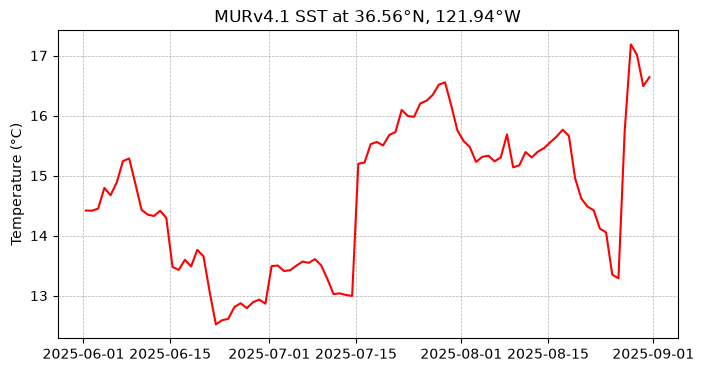

In [47]:
# SST figure for 2025
fig = plt.figure(figsize=(8,4))
plt.plot(dates_2025, sst_2025, color='red')
plt.ylabel('Temperature (°C)')
plt.grid(linestyle='--', linewidth=0.5)
plt.title(f'MURv4.1 SST at {latitude[lat_index]:.2f}°N, {-longitude[lon_index]:.2f}°W')
plt.show()

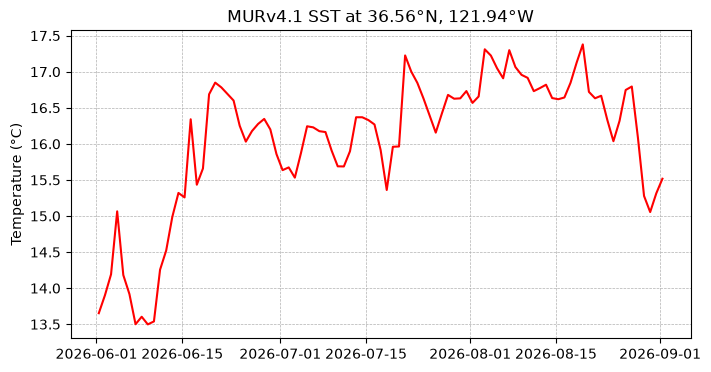

In [48]:




# SST figure for 2026
fig = plt.figure(figsize=(8,4))
plt.plot(dates_2026, sst_2026, color='red')
plt.ylabel('Temperature (°C)')
plt.grid(linestyle='--', linewidth=0.5)
plt.title(f'MURv4.1 SST at {latitude[lat_index]:.2f}°N, {-longitude[lon_index]:.2f}°W')
plt.show()

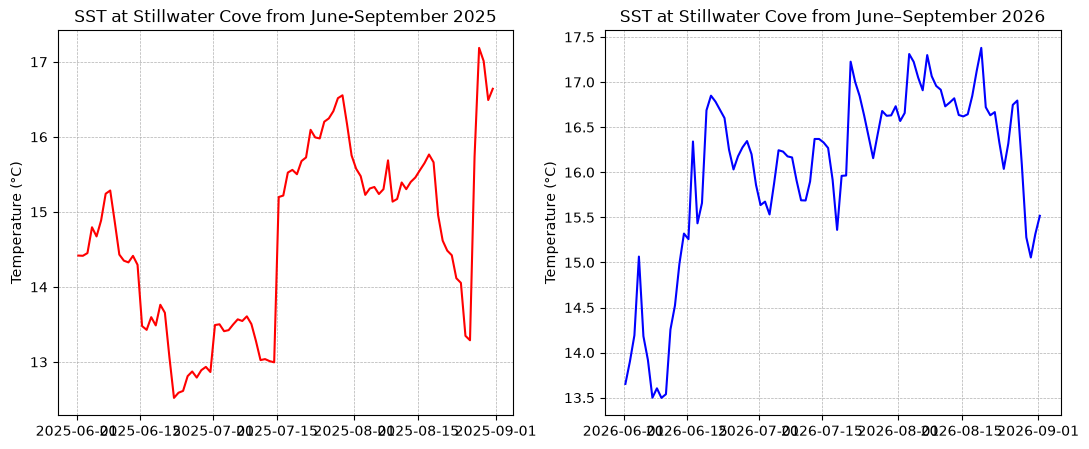

In [56]:
#figure
fig = plt.figure(figsize=(20,5))

#plot 2025 data
ax1 = fig.add_subplot(1,3,1)
ax1.plot(dates_2025, sst_2025, color='red')
ax1.set_ylabel('Temperature (°C)')
ax1.set_title('SST at Stillwater Cove from June-September 2025')
ax1.grid(linestyle='--', linewidth=0.5)

#plot 2026 SST
ax2 = fig.add_subplot(1, 3, 2)
ax2.plot(dates_2026, sst_2026, color='blue')
ax2.set_ylabel('Temperature (°C)')
ax2.set_title('SST at Stillwater Cove from June–September 2026')
ax2.grid(linestyle='--', linewidth=0.5)

plt.show()